# 재난 사진에서 ‘심각’ 판정이 바뀐 이유
**CrisisMMD · Colab 독립 검산**  
이 노트북은 등급 하락을 같은 사진끼리 대조하고, 실제 박물관 사진 한 장의 모델 출력을 다시 계산한다. 이어 세 모델이 원본 사진에서 만든 ‘심각’ 목록을 이미지 ID로 비교한다.

시험 사진은 529장, 정답과 원본 예측이 모두 심각인 사진은 259장이다. 원본과 보관된 박물관 입력의 점수는 런타임에서 계산하며, 전체 FGSM·BIM 비교는 기존 실험의 사진별 예측 기록을 사용한다. [모델 및 실험 자료 v1.0.1](https://github.com/rhcp030418/CrisisMMD_FGSM_BIM/releases/tag/v1.0.1) · [QCRI 데이터](https://huggingface.co/datasets/QCRI/CrisisMMD)

## 한 단계 하락과 두 단계 하락
행은 FGSM 판정, 열은 같은 사진의 BIM 판정이다. 대각선에서 벗어난 칸을 읽으면 최종 등급이 달라진 사진 수를 알 수 있다.

In [1]:
#@title 릴리스 검증과 등급 전이표
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO
import hashlib, json, time, zipfile
import numpy as np
import pandas as pd
import requests
from PIL import Image, ImageOps
import torch, torchvision

base = Path("crisismmd_colab_cache")
base.mkdir(exist_ok=True)
release = base / "submission-v1.0.1.zip"
expected = "f31291308f1a1706486f6fee1507bf0a54f35c1c3f5359fe145592411487fd9f"
url = "https://github.com/rhcp030418/CrisisMMD_FGSM_BIM/releases/download/v1.0.1/CrisisMMD-full-submission.zip"
def digest(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
if not release.exists() or digest(release) != expected:
    tmp = release.with_suffix(".part")
    with requests.get(url, stream=True, timeout=90) as response, tmp.open("wb") as out:
        response.raise_for_status()
        for chunk in response.iter_content(2**20):
            out.write(chunk)
    assert digest(tmp) == expected, "릴리스 해시가 다릅니다."
    tmp.replace(release)
bundle = zipfile.ZipFile(release)
saved = pd.read_csv(bundle.open("comparison/paired_predictions.csv"), dtype={"image_id":str})
assert not saved.duplicated(["model","image_id"]).any()
assert saved.groupby("model").size().to_dict() == {"standard":529, "noise":529, "fgsm":529}
original = saved.query("model == 'standard' and truth == 2 and clean == 2")
assert len(original) == 259

"""Display the two independent comparisons and the archived museum example."""
import base64
from html import escape
from IPython.display import HTML, display

def result_card(title, description, body):
    css = """
    <style>
    .cm-result {background:#fff;color:#192e36;border:1px solid #cad5d9;border-radius:8px;
      font-family:system-ui,sans-serif;line-height:1.5;padding:14px 18px;margin:4px 0;max-width:790px;}
    .cm-result h3 {font-size:18px;line-height:1.4;color:#203a46;margin:0 0 3px;font-weight:750}
    .cm-result p {font-size:13px;margin:3px 0 10px;color:#3b515a}
    .cm-result table {border-collapse:collapse;width:100%;font-size:13px;color:#1c313b;margin:4px 0 8px}
    .cm-result th,.cm-result td {border:0;border-bottom:1px solid #dbe5e7;padding:5px 6px;text-align:right}
    .cm-result th {background:#edf3f5;font-weight:650;color:#223b47}
    .cm-result th:first-child,.cm-result td:first-child{text-align:left}
    .cm-result .photos{display:flex;gap:8px;align-items:flex-start}
    .cm-result figure {margin:3px 0;min-width:0;flex:1}
    .cm-result img{width:100%;max-width:180px;height:auto;display:block;border-radius:3px}
    .cm-result figcaption{font-size:13px;line-height:1.5;color:#253e4a;padding-top:4px}
    .cm-result small {font-size:12px;color:#445e6a}
    </style>
    """
    display(HTML(css + '<section class="cm-result"><h3>' + title +
                 "</h3><p>" + description + "</p>" + body + "</section>"))

def table_html(headers, rows):
    head = "".join("<th>"+escape(str(v))+"</th>" for v in headers)
    body = "".join("<tr>"+"".join("<td>"+escape(str(v))+"</td>" for v in row)+"</tr>" for row in rows)
    return "<table><thead><tr>"+head+"</tr></thead><tbody>"+body+"</tbody></table>"

names = ["거의 없음", "경미", "심각"]
transition = pd.crosstab(original.fgsm_4, original.bim_4).reindex(index=[2,1,0],columns=[2,1,0],fill_value=0)
results_record = {"transition":transition.to_numpy().tolist(), "cohort":len(original)}
rows = [[names[level],*transition.loc[level].tolist(), int(transition.loc[level].sum())] for level in [2,1,0]]
rows.append(["BIM 합계",*transition.sum().astype(int).tolist(),len(original)])
result_card("같은 사진에서 FGSM과 BIM의 등급은 어떻게 달라졌나",
            "기존 예측 재집계 · 원래 심각을 맞힌 259장 · 픽셀 변화 한도 4/255",
            table_html(["FGSM ↓ / BIM →","심각","경미","거의 없음","FGSM 합계"],rows))

FGSM ↓ / BIM →,심각,경미,거의 없음,FGSM 합계
심각,0,9,15,24
경미,0,130,4,134
거의 없음,0,14,87,101
BIM 합계,0,153,106,259


## 시험 사진 529장과 세 모델 다시 읽기
QCRI에 공개된 원본 파일, 전처리된 픽셀, 릴리스의 가중치를 각각 해시로 대조한다. 모델은 평가 모드에서 원본 사진의 등급을 새로 예측한다.

In [2]:
#@title 시험 사진 및 픽셀 해시 확인
revision = "10a5626ba112ab9c50369c473a2062bcf205d708"
hub = "https://huggingface.co/datasets/QCRI/CrisisMMD/resolve/" + revision + "/"
manifest = json.loads(bundle.read("split_manifest.json"))
test = [r for r in manifest if r["included"] and r["split"] == "test"]
assert len(test) == 529
cache = base / "test_rgb"
cache.mkdir(exist_ok=True)
def load_photo(row):
    p = cache / (row["image_id"] + ".jpg")
    raw = p.read_bytes() if p.exists() else b""
    if hashlib.sha256(raw).hexdigest() != row["sha256"]:
        for attempt in range(5):
            try:
                resp = requests.get(hub + row["image_path"], timeout=45)
                resp.raise_for_status()
                raw = resp.content
                assert hashlib.sha256(raw).hexdigest() == row["sha256"], row["image_id"]
                p.write_bytes(raw)
                break
            except requests.RequestException:
                if attempt == 4:
                    raise
                time.sleep(3 * 2**attempt)
    with Image.open(BytesIO(raw)) as im:
        rgb = np.asarray(ImageOps.exif_transpose(im).convert("RGB").resize((160,160),Image.Resampling.BILINEAR))
    return rgb, hashlib.sha256(rgb.tobytes()).hexdigest() == row["pixel_sha256"]

with ThreadPoolExecutor(max_workers=6) as pool:
    photos = []
    for i, photo in enumerate(pool.map(load_photo, test),1):
        photos.append(photo)
        if i % 100 == 0 or i == len(test):
            print(f"원본 해시 확인 {i}/{len(test)}", flush=True)
pixels = torch.from_numpy(np.stack([rgb for rgb, match in photos])).permute(0,3,1,2)
print("전처리 후 픽셀이 기존 환경과 일치한 사진:", sum(match for rgb, match in photos), "/", len(test))

원본 해시 확인 100/529
원본 해시 확인 200/529
원본 해시 확인 300/529
원본 해시 확인 400/529
원본 해시 확인 500/529
원본 해시 확인 529/529
전처리 후 픽셀이 기존 환경과 일치한 사진: 529 / 529


In [3]:
#@title 원본 사진의 세 모델 재추론
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class DamageModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = torchvision.models.resnet18(weights=None)
        self.backbone.fc = torch.nn.Linear(self.backbone.fc.in_features,3)
        self.register_buffer("mean",torch.tensor([.485,.456,.406]).view(1,3,1,1))
        self.register_buffer("std",torch.tensor([.229,.224,.225]).view(1,3,1,1))
    def forward(self, batch):
        return self.backbone((batch - self.mean) / self.std)

print("실행 장치:", device, "/ torch",torch.__version__, "/ torchvision",torchvision.__version__)
ids = [row["image_id"] for row in test]
labels = ["little_or_no_damage","mild_damage","severe_damage"]
truth = np.array([labels.index(row["label"]) for row in test])
rows = []
new_clean = {}
for name, folder in [("standard","results"),("noise","defense/noise"),("fgsm","defense/fgsm")]:
    checkpoint = bundle.read(folder + "/model.pt")
    audit = json.loads(bundle.read(folder + "/audit.json"))
    assert hashlib.sha256(checkpoint).hexdigest() == audit["checkpoint_sha256"]
    model = DamageModel()
    model.load_state_dict(torch.load(BytesIO(checkpoint),map_location="cpu",weights_only=True)["weights"])
    model.to(device).eval()
    with torch.inference_mode():
        predictions = torch.cat([model(batch.to(device).float()/255).argmax(1).cpu() for batch in pixels.split(32)]).numpy()
    new_clean[name] = predictions.copy()
    recorded = saved[saved.model == name].set_index("image_id").loc[ids]
    assert np.array_equal(truth, recorded.truth)
    cm = np.bincount(3*truth+predictions,minlength=9).reshape(3,3)
    f1 = 2*np.diag(cm)/np.maximum(1,cm.sum(0)+cm.sum(1))
    rows.append([name,int((predictions==recorded.clean).sum()),round(float((truth==predictions).mean()),4),
                 round(float(f1.mean()),4),int(cm[2,2]),int(cm[:2,2].sum())])
result = pd.DataFrame(rows,columns=["model","matches_of_529","accuracy","macro_F1","true_severe","false_alarms"])

실행 장치: cpu / torch 2.14.1+cpu / torchvision 0.29.1+cpu


## 침수된 박물관에서 달라진 판정
릴리스에 보관된 동일 장면의 세 입력을 같은 모델에 넣는다. 3개의 점수 중 가장 높은 등급이 모델 판정이다. 이는 특정 사진 한 장의 관찰이다.

침수된 박물관 한 장을 모델에 다시 넣은 결과

허리케인 하비 · 정답 심각 · 동일한 일반 학습 모델

원본
판정 · 심각
심각 점수 91.6%
FGSM 보관 입력
판정 · 심각
심각 점수 43.2%
BIM 보관 입력
판정 · 경미
심각 점수 0.4%
심각 점수는 모델의 세 등급 소프트맥스 출력 중 심각에 배정한 값이다.
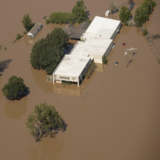
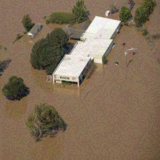
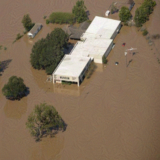

In [4]:
#@title 박물관 입력으로 세 등급 점수 재계산
from io import BytesIO

museum_meta = json.loads(bundle.read("figures/figure_labels.json"))[0]
case_id = str(museum_meta["image_id"])
case_index = ids.index(case_id)
assert truth[case_index] == 2
with np.load(BytesIO(bundle.read("comparison/museum_inputs.npz")), allow_pickle=False) as inputs:
    modes = ["clean","fgsm","bim"]
    fixed = np.concatenate([inputs[m] for m in modes])
assert fixed.shape == (3,160,160,3)
assert np.allclose(fixed[0], pixels[case_index].permute(1,2,0).numpy()/255, atol=1e-6)
checkpoint = torch.load(BytesIO(bundle.read("results/model.pt")), map_location="cpu", weights_only=True)
single_model = DamageModel()
single_model.load_state_dict(checkpoint["weights"])
single_model.to(device).eval()
with torch.inference_mode():
    scores = single_model(torch.from_numpy(fixed).permute(0,3,1,2).to(device)).softmax(1).cpu().numpy()

image_cards = []
case_rows = []
for index, (mode, label) in enumerate(zip(modes, ["원본","FGSM 보관 입력","BIM 보관 입력"])):
    probs = scores[index]
    grade = int(probs.argmax())
    assert grade == int(museum_meta[mode])
    rgb = Image.fromarray(np.uint8(np.round(fixed[index]*255)))
    image_bytes = BytesIO()
    rgb.save(image_bytes,format="PNG")
    url = "data:image/png;base64," + base64.b64encode(image_bytes.getvalue()).decode("ascii")
    image_cards.append(f'<figure><img src="{url}" alt="{label} 박물관 침수 사진">'
                       f'<figcaption>{label}<br><b>판정 · {names[grade]}</b><br>심각 점수 {100*probs[2]:.1f}%</figcaption></figure>')
    case_rows.append({"input":mode,"prediction":grade,"scores":probs.tolist()})
results_record["case"] = case_rows
result_card("침수된 박물관 한 장을 모델에 다시 넣은 결과",
            "허리케인 하비 · 정답 심각 · 동일한 일반 학습 모델",
            '<div class="photos">'+"".join(image_cards)+'</div>'
            '<small>심각 점수는 모델의 세 등급 소프트맥스 출력 중 심각에 배정한 값이다.</small>')

## 방어 학습 뒤 검토 목록에서 바뀐 사진
‘심각’ 목록에 새로 포함된 사진과 제외된 사진을 이미지 ID로 짝짓는다. 실제 심각인 사진과 나머지 사진을 구분해 적중과 오경보의 변화를 계산한다.

In [5]:
#@title 방어 학습 전후의 적중 및 오경보 대조
from itertools import product

labels_ko = {"standard":"일반 학습","noise":"노이즈 학습","fgsm":"FGSM 학습"}
head = ["학습 방식","예측 일치","심각 적중","오경보","심각 목록"]
display_rows = []
for row in result.itertuples():
    display_rows.append([labels_ko[row.model], f"{row.matches_of_529}/529",
                         int(row.true_severe),int(row.false_alarms),int(row.true_severe+row.false_alarms)])
alert = {key:values==2 for key,values in new_clean.items()}
group_counts = {}
for group, mask in [("severe",truth==2),("other",truth!=2)]:
    group_counts[group] = {
        direction:int((mask & condition).sum())
        for direction, condition in [
            ("new",~alert["standard"] & alert["fgsm"]),
            ("removed",alert["standard"] & ~alert["fgsm"]),
            ("both",alert["standard"] & alert["fgsm"]),
            ("neither",~alert["standard"] & ~alert["fgsm"])
        ]
    }
results_record.update(clean_models=result.to_dict(orient="records"), paired_alerts=group_counts,
                      device=str(device),torch=str(torch.__version__),torchvision=str(torchvision.__version__),
                      matched_pixels=int(sum(match for _,match in photos)),test_n=len(test))
g, h = group_counts["severe"],group_counts["other"]
result_card("방어 학습 뒤 어떤 사진이 검토 목록에 더 들어왔나",
            "원본 시험 사진 529장 재추론 · 오경보는 경미하거나 피해가 거의 없는 사진을 심각으로 분류한 건수",
            table_html(head,display_rows) +
            f'<p>실제 심각 사진은 {g["new"]}장 새로 들어오고 {g["removed"]}장 빠졌다. '
            f'오경보는 {h["new"]}장 새로 들어오고 {h["removed"]}장 빠졌다.</p>')
record_text = json.dumps(results_record,ensure_ascii=False,indent=2)
Path("colab_validation.json").write_text(record_text,encoding="utf-8")
display(HTML('<details><summary>검산 기록 JSON</summary><pre>'+escape(record_text)+'</pre></details>'))

학습 방식,예측 일치,심각 적중,오경보,심각 목록
일반 학습,529/529,259,79,338
노이즈 학습,529/529,263,97,360
FGSM 학습,529/529,328,190,518


검산 기록 JSON
{
  "transition": [
    [
      0,
      9,
      15
    ],
    [
      0,
      130,
      4
    ],
    [
      0,
      14,
      87
    ]
  ],
  "cohort": 259,
  "case": [
    {
      "input": "clean",
      "prediction": 2,
      "scores": [
        0.02543083392083645,
        0.05817490071058273,
        0.9163942337036133
      ]
    },
    {
      "input": "fgsm",
      "prediction": 2,
      "scores": [
        0.21975132822990417,
        0.3477524220943451,
        0.43249624967575073
      ]
    },
    {
      "input": "bim",
      "prediction": 1,
      "scores": [
        0.13493837416172028,
        0.8613126277923584,
        0.0037490217946469784
      ]
    }
  ],
  "clean_models": [
    {
      "model": "standard",
      "matches_of_529": 529,
      "accuracy": 0.6163,
      "macro_F1": 0.4897,
      "true_severe": 259,
      "false_alarms": 79
    },
    {
      "model": "noise",
      "matches_of_529": 529,
      "accuracy": 0.6106,
      "macro_F1": 0.4745,
      "true_severe": 263,
      "false_alarms": 97
    },
    {
      "model": "fgsm",
      "matches_of_529": 529,
      "accuracy": 0.6314,
      "macro_F1": 0.3046,
      "true_severe": 328,
      "false_alarms": 190
    }
  ],
  "paired_alerts": {
    "severe": {
      "new": 69,
      "removed": 0,
      "both": 259,
      "neither": 4
    },
    "other": {
      "new": 112,
      "removed": 1,
      "both": 78,
      "neither": 6
    }
  },
  "device": "cpu",
  "torch": "2.14.1+cpu",
  "torchvision": "0.29.1+cpu",
  "matched_pixels": 529,
  "test_n": 529
}